# Density and temperature evolution
4×4 spatial maps matching PS.ipynb: the same figure size, tight spacing, seismic colormap, top time titles, and thin colorbars with quantity labels on the right. Rows: ne, ni, Te, Ti. Columns: the four saved steps.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import ScalarFormatter
from turbos.sim.vpic.vpic import VPIC

run = VPIC(
    info_file="/work/space_plasma/users/goodwill/KH/info",
    data_dirs={
        "fields": "/lustre/scratch/goodwill/KH/field_hdf5",
        "hydro": "/lustre/scratch/goodwill/KH/hydro_hdf5",
    },
)

In [2]:
def scalar_temperature(T):
    """Average three diagonal temperature components; T already has temperature units."""
    if {"i", "j"}.issubset(T.dims):
        if T.sizes["i"] != 3 or T.sizes["j"] != 3:
            raise ValueError(f"Expected a 3x3 temperature tensor, got {T.sizes}")
        labeled = all(
            d in T.coords and all(k in T[d].values for k in ("x", "y", "z"))
            for d in ("i", "j")
        )
        if labeled:
            diagonal = [T.sel(i=k, j=k, drop=True) for k in ("x", "y", "z")]
        else:
            # Unlabeled tensor axes are assumed ordered x, y, z.
            diagonal = [T.isel(i=k, j=k, drop=True) for k in range(3)]
        return (diagonal[0] + diagonal[1] + diagonal[2]) / 3.0
    if set(T.dims) == {"x", "y"}:
        return T  # Also accept a reader that already returns scalar temperature.
    raise ValueError(f"Expected scalar (x,y) or tensor (x,y,i,j) temperature, got {T.dims}")


steps = [140000, 240000, 320000, 480000]
variables = ["ne", "Te", "Ti"]
labels = [r"$n_e$", r"$T_e$", r"$T_i$"]
coordinate_divisor = 10.0  # d_e -> d_i for mi/me=100; use 1 if already in d_i.
output_path = Path("/home/2480/turbos/projects/KHI_2D/fig/nT.png")
# Optional fixed limits per row; None uses the finite min/max over all four times.
color_limits = {name: None for name in variables}
# Example: color_limits["ne"] = (0.5, 2.0)

snapshots = []
time_labels = []
for step in steps:
    print(f"Loading step {step}")
    ds = run.load_step(step, variables)
    # Load once per time, rather than once for each row.
    selected = ds[variables].copy()
    for var in ("Te", "Ti"):
        selected[var] = scalar_temperature(selected[var])
    # Drop tensor coordinates after reducing both temperature tensors.
    selected = selected.drop_dims([d for d in ("i", "j") if d in selected.dims])
    for var in variables:
        if set(selected[var].dims) != {"x", "y"}:
            raise ValueError(f"{var} must be a scalar (x, y) field; got {selected[var].dims}")
    snapshots.append(selected.transpose("x", "y").load())
    if "time" in ds.attrs:
        time_labels.append(rf"$t = {float(ds.attrs['time']):.2f}$")
    elif "time" in ds.coords and ds["time"].size == 1:
        time_labels.append(rf"$t = {float(ds['time'].values.item()):.2f}$")
    else:
        time_labels.append(f"step = {step}")

norms = {}
for var in variables:
    limits = color_limits[var]
    if limits is None:
        lo, hi = np.inf, -np.inf
        for ds in snapshots:
            values = ds[var].values
            finite = values[np.isfinite(values)]
            if finite.size:
                lo = min(lo, float(finite.min()))
                hi = max(hi, float(finite.max()))
        if not np.isfinite(lo) or not np.isfinite(hi):
            raise ValueError(f"No finite values for {var} at any time")
        if lo == hi:
            pad = max(abs(lo) * 0.01, 1e-12)
            lo, hi = lo - pad, hi + pad
    else:
        lo, hi = limits
    if not np.isfinite(lo) or not np.isfinite(hi) or lo >= hi:
        raise ValueError(f"Invalid color limits for {var}: {(lo, hi)}")
    norms[var] = Normalize(vmin=lo, vmax=hi)
    print(f"{var}: shared color limits [{lo:g}, {hi:g}]")

Loading step 140000
Loading step 240000
Loading step 320000
Loading step 480000
ne: shared color limits [0.233555, 1.82718]
Te: shared color limits [0.00243017, 0.0521692]
Ti: shared color limits [0.00342774, 0.0613124]


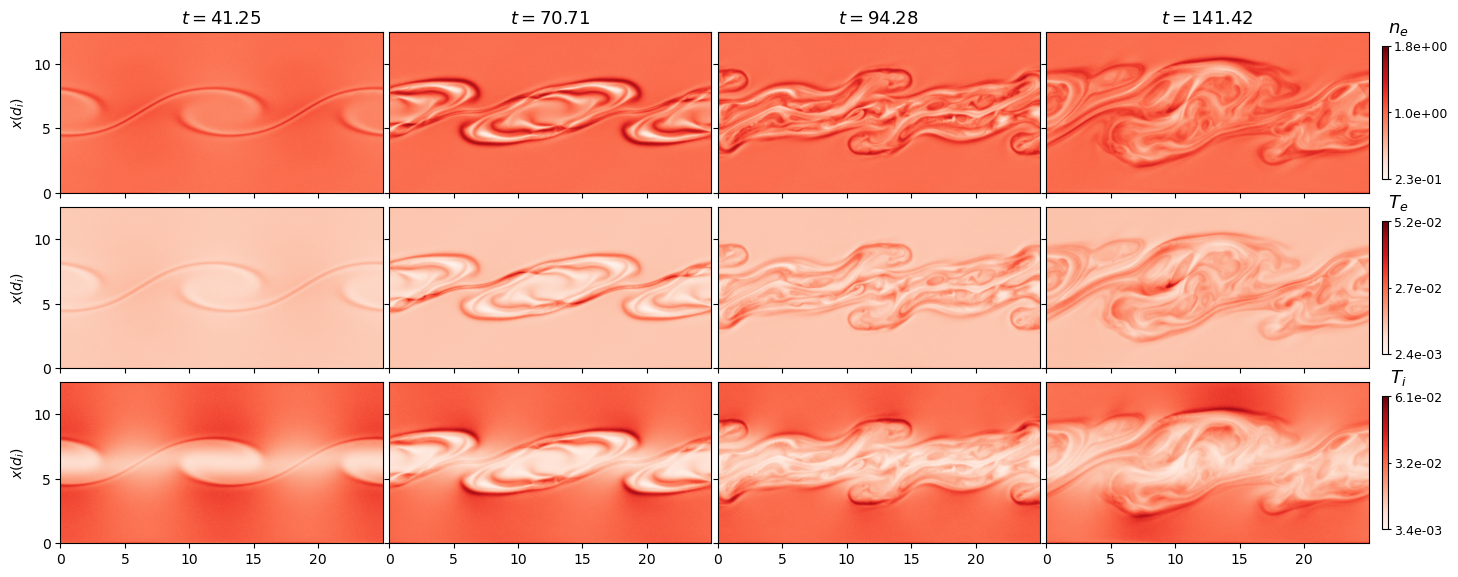

Saved /home/2480/turbos/projects/KHI_2D/fig/nT.png


In [3]:
def cell_edges(values):
    """Pixel edges from cell-center coordinates; avoid half-cell extent shifts."""
    values = np.asarray(values, dtype=float) / coordinate_divisor
    if values.ndim != 1 or values.size < 2:
        raise ValueError("Need at least two coordinate centers per spatial axis")
    middle = 0.5 * (values[:-1] + values[1:])
    return np.r_[values[0] - 0.5 * (values[1] - values[0]),
                 middle,
                 values[-1] + 0.5 * (values[-1] - values[-2])]


fig, ax = plt.subplots(
    3, 4,
    figsize=(16, 6),
    sharex=True,
    sharey=True,
    layout=None,
    gridspec_kw={"wspace": 0.02, "hspace": 0.02},
)
fig.subplots_adjust(
    left=0.07, right=0.90, bottom=0.08, top=0.95,
    wspace=0.02, hspace=0.02,
)

for row, (var, label) in enumerate(zip(variables, labels)):
    for col, ds in enumerate(snapshots):
        y_edges = cell_edges(ds.y.values)
        x_edges = cell_edges(ds.x.values)
        im = ax[row, col].imshow(
            ds[var].transpose("x", "y").values,
            cmap="Reds",
            origin="lower",
            interpolation="auto",
            extent=[y_edges[0], y_edges[-1], x_edges[0], x_edges[-1]],
            norm=norms[var],
            aspect="equal",
        )
        if row == 0:
            ax[row, col].set_title(time_labels[col], fontsize=13)
        if row == 3:
            ax[row, col].set_xlabel(r"$y(d_i)$")
        if col == 0:
            ax[row, col].set_ylabel(r"$x(d_i)$")

    lo, hi = norms[var].vmin, norms[var].vmax
    cbar = fig.colorbar(
        im,
        ax=ax[row, :],
        fraction=0.005,
        pad=0.01,
        ticks=[lo, (lo + hi) / 2, hi],
        format="%.1e",
    )
    cbar.ax.tick_params(labelsize=9, pad=2, length=2)
    cbar.ax.set_title(label, fontsize=13, pad=10, x=2.5)

output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {output_path}")


Te and Ti are temperature tensors in the VPIC reader mapping. The plotted scalar temperature is (Txx + Tyy + Tzz)/3, including the out-of-plane component. No additional division by density is applied because these fields already have temperature units. Off-diagonal components do not enter the scalar temperature.

Each row shares its color limits across the four times. Coordinates are divided by 10 as in PS.ipynb (for mi/me=100 and input coordinates in d_e). No additional filtering or normalization is applied.
